Polynomial regression - exercise
1. Load the diamonds dataset that was the result of the "Linear Regression - exercise 2" - diamonds_preprocessed.csv.
2. Import all necessary methods from libraries (or modules from these libraries).
3. Divide the dataset into training and test datasets.
4. Using the appropriate tools of the Scikit-learn library, generate polynomial variables. Select the appropriate degree of the polynomial.
    For each variant:
     
     train a linear regression model using the new set of variables,

     Calculate the metrics R2, MAE, MSE and RMSE. Compare these values with the metrics of previous models.

In [45]:
import pandas as pd
diamonds_pr_df = pd.read_csv("data/diamonds_preprocessed.csv")
diamonds_pr_df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,2,1,3,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,1,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,1,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,5,5,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,6,3,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53894,0.72,2,0,2,60.8,57.0,2757,5.75,5.76,3.50
53895,0.72,1,0,2,63.1,55.0,2757,5.69,5.75,3.61
53896,0.70,4,0,2,62.8,60.0,2757,5.66,5.68,3.56
53897,0.86,3,4,3,61.0,58.0,2757,6.15,6.12,3.74


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

In [47]:
X = diamonds_pr_df.drop("price", axis=1)
y = diamonds_pr_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [49]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)
lin_reg.score(X_test, y_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"R2: {r2}")
print(f"RMSE: {rmse}")

R2: 0.8892348217787043
RMSE: 1298.801349861814


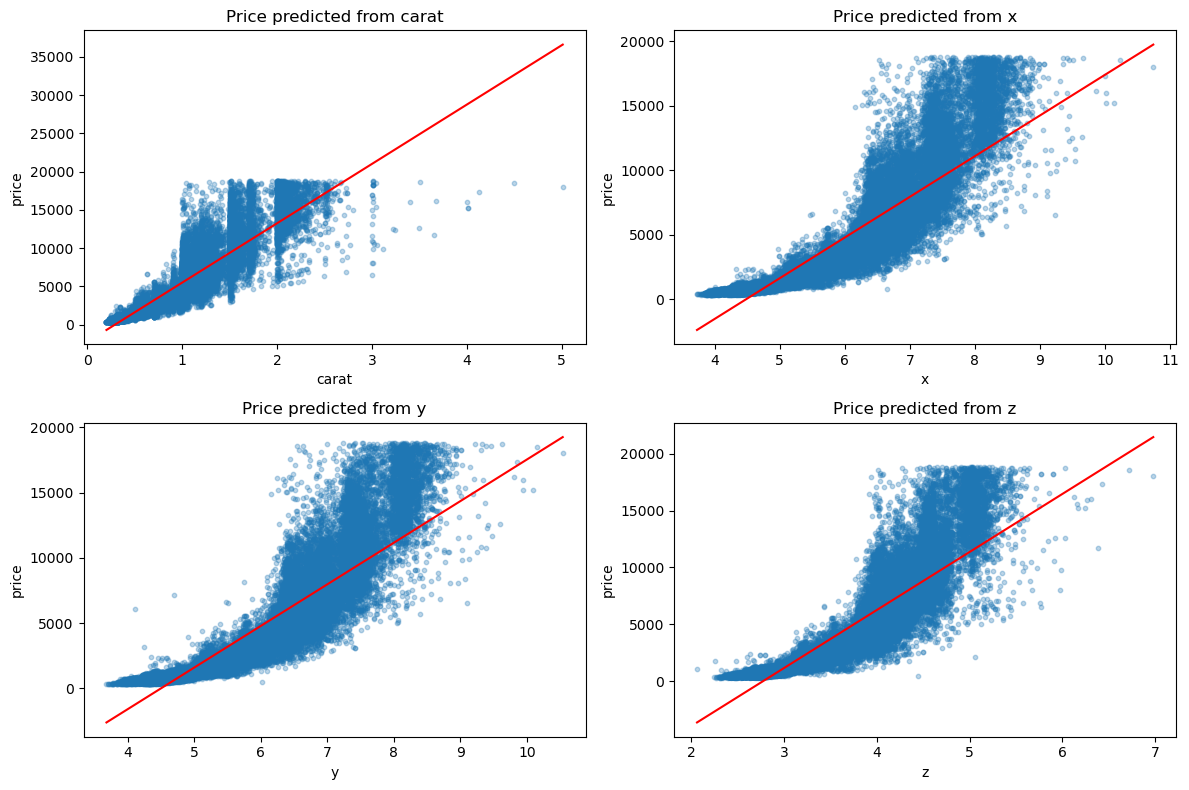

In [ ]:
predictors = ["carat", "x", "y", "z"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.ravel(), predictors):
    X_column = diamonds_pr_df[[column]]
    y_price = diamonds_pr_df["price"]

    model = LinearRegression()
    model.fit(X_column, y_price)

    y_pred_price = model.predict(X_column)

    sort_index = np.argsort(X_column[column].to_numpy())

    ax.scatter(
        X_column[column],
        y_price,
        s=10,
        alpha=0.3
    )
    ax.plot(
        X_column[column].to_numpy()[sort_index],
        y_pred_price[sort_index],
        color="red"
    )

    ax.set_xlabel(column)
    ax.set_ylabel("price")
    ax.set_title(f"Price predicted from {column}")

plt.tight_layout()
plt.show()



Each subplot fits a separate linear regression using one column to predict price

In [51]:
# Create PolynomialFeatures object

polynomial_features = PolynomialFeatures(degree=2)

# Fit and transform on our data
X_poly = polynomial_features.fit_transform(X)
model_poly = LinearRegression()
model_poly.fit(X_poly, y)
y_pred_poly = model_poly.predict(X_poly)
r2_poly = r2_score(y, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y, y_pred_poly))

print(f"R2_Polynomial: {r2_poly}")
print(f"RMSE_Polynomial: {rmse_poly}")

R2_Polynomial: 0.9330281484316896
RMSE_Polynomial: 1031.8362509309723


### Polynomial Regression Results

The test RMSE improved from **1298** before using polynomial features to approximately **1013** afterward. The polynomial model achieved an R² score of **0.9330**, indicating improved model performance and lower prediction error.

Polynomial regression with degree 2 creates additional squared and interaction features, allowing the model to capture non-linear relationships in the data.